# Student Stress Profiles: An Unsupervised Learning Study
**Author:** Zuhair Syd  
**AI Pair Programmer / Technical Assistant:** Google Gemini  
**Course:** DATA 3441 / DATA 3441: Data Problems  
**Date:** Fall 2026  

---
### Research Question:
> *"Can unsupervised learning identify distinct student stress profiles, which variables contribute the most to profile identification, and does this change between genders?"*

This notebook provides the complete exploratory data analysis, feature preprocessing, correlation verification, model benchmarking (K-Means, Agglomerative Hierarchical, Gaussian Mixture Models), and gender disparity evaluations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
from scipy.stats import chi2_contingency
from matplotlib.colors import LinearSegmentedColormap

# Aesthetics & Color Palette (Gold & Rose-Pink)
GOLD = '#D4AF37'
ROSE_PINK = '#E84393'
SOFT_PINK = '#F8A5C2'
DARK_GOLD = '#B8860B'
DEEP_ROSE = '#C2185B'
LIGHT_CREAM = '#FFFDF9'
DARK_TEXT = '#2C3E50'

sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams['figure.facecolor'] = LIGHT_CREAM


## 1. Data Loading & Initial Inspection

In [2]:
# Load raw survey dataset
df = pd.read_csv('survey.csv')

# Clean any trailing whitespace in column names
df.columns = df.columns.str.strip()

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nMissing values per column:")
print(df.isnull().sum())
df.head(5)


Dataset Dimensions: 87 rows, 21 columns

Missing values per column:
gender                      0
age                         0
university                  0
degree_level                0
degree_major                0
academic_year               0
cgpa                        0
residential_status          0
campus_discrimination       0
sports_engagement           0
average_sleep               0
study_satisfaction          0
academic_workload           0
academic_pressure           0
financial_concerns          0
social_relationships        0
depression                  0
anxiety                     0
isolation                   0
future_insecurity           0
stress_relief_activities    0
dtype: int64


,gender,age,university,degree_level,degree_major,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,...,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity,stress_relief_activities
0,Male,20,PU,Undergraduate,Data Science,2nd year,3.0-3.5,Off-Campus,No,No Sports,...,5,4,5,4,3,2,1,1,2,"Religious Activities, Social Connections, Onli..."
1,Male,20,UET,Postgraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,No,1-3 times,...,5,4,4,1,3,3,3,3,4,Online Entertainment
2,Male,20,FAST,Undergraduate,Computer Science,3rd year,2.5-3.0,Off-Campus,No,1-3 times,...,5,5,5,3,4,2,3,3,1,"Religious Activities, Sports and Fitness, Onli..."
3,Male,20,UET,Undergraduate,Computer Science,3rd year,2.5-3.0,On-Campus,No,No Sports,...,3,5,4,4,1,5,5,5,3,Online Entertainment
4,Female,20,UET,Undergraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,Yes,No Sports,...,3,5,5,2,3,5,5,4,4,Online Entertainment


## 2. Feature Engineering & Multi-Select Encoding

The `stress_relief_activities` feature allows multiple selections per student, resulting in comma-separated strings. We apply `MultiLabelBinarizer` to extract independent binary indicators for each coping mechanism without exploding category cardinality.


In [3]:
# Split comma-separated responses
activities_series = df['stress_relief_activities'].dropna().apply(
    lambda x: [item.strip() for item in x.split(',')]
)

# Apply MultiLabelBinarizer
mlb = MultiLabelBinarizer()
sr_encoded = pd.DataFrame(
    mlb.fit_transform(activities_series),
    columns=['sr_' + c.replace(' ', '_').lower() for c in mlb.classes_],
    index=df.index
)

print(f"Discovered {len(mlb.classes_)} unique stress relief activities:")
print(sr_encoded.sum().sort_values(ascending=False))


Discovered 8 unique stress relief activities:
sr_religious_activities    46
sr_online_entertainment    37
sr_social_connections      33
sr_sleep                   20
sr_sports_and_fitness      20
sr_outdoor_activities      19
sr_creative_outlets        10
sr_nothing                  1
dtype: int64


In [4]:
# Binary encodings
df['gender_male'] = (df['gender'] == 'Male').astype(int)
df['residence_on_campus'] = (df['residential_status'] == 'On-Campus').astype(int)
df['discrimination_yes'] = (df['campus_discrimination'] == 'Yes').astype(int)

# Ordinal encodings preserving scale progression
cgpa_map = {'0.0-0.0': 0, '1.5-2.0': 1, '2.0-2.5': 2, '2.5-3.0': 3, '3.0-3.5': 4, '3.5-4.0': 5}
year_map = {'1st year': 1, '2nd year': 2, '3rd year': 3, '4th year': 4}
sports_map = {'No Sports': 0, '1-3 times': 1, '4-6 times': 2, '7+ times': 3}
sleep_map = {'2-4 hrs': 0, '4-6 hrs': 1, '7-8 hrs': 2}

df['cgpa_encoded'] = df['cgpa'].map(cgpa_map)
df['academic_year_encoded'] = df['academic_year'].map(year_map)
df['sports_encoded'] = df['sports_engagement'].map(sports_map)
df['sleep_encoded'] = df['average_sleep'].map(sleep_map)

# Merge preprocessed features
preprocessed_df = pd.concat([df, sr_encoded], axis=1)
preprocessed_df.to_csv('survey_preprocessed.csv', index=False)
print("Preprocessing complete. Full dataset encoded successfully.")


Preprocessing complete. Full dataset encoded successfully.


## 3. Exploratory Data Analysis (EDA)

Visualizing lifestyle habits (sports, sleep) alongside academic stressors (workload, satisfaction) to establish baseline distributions.


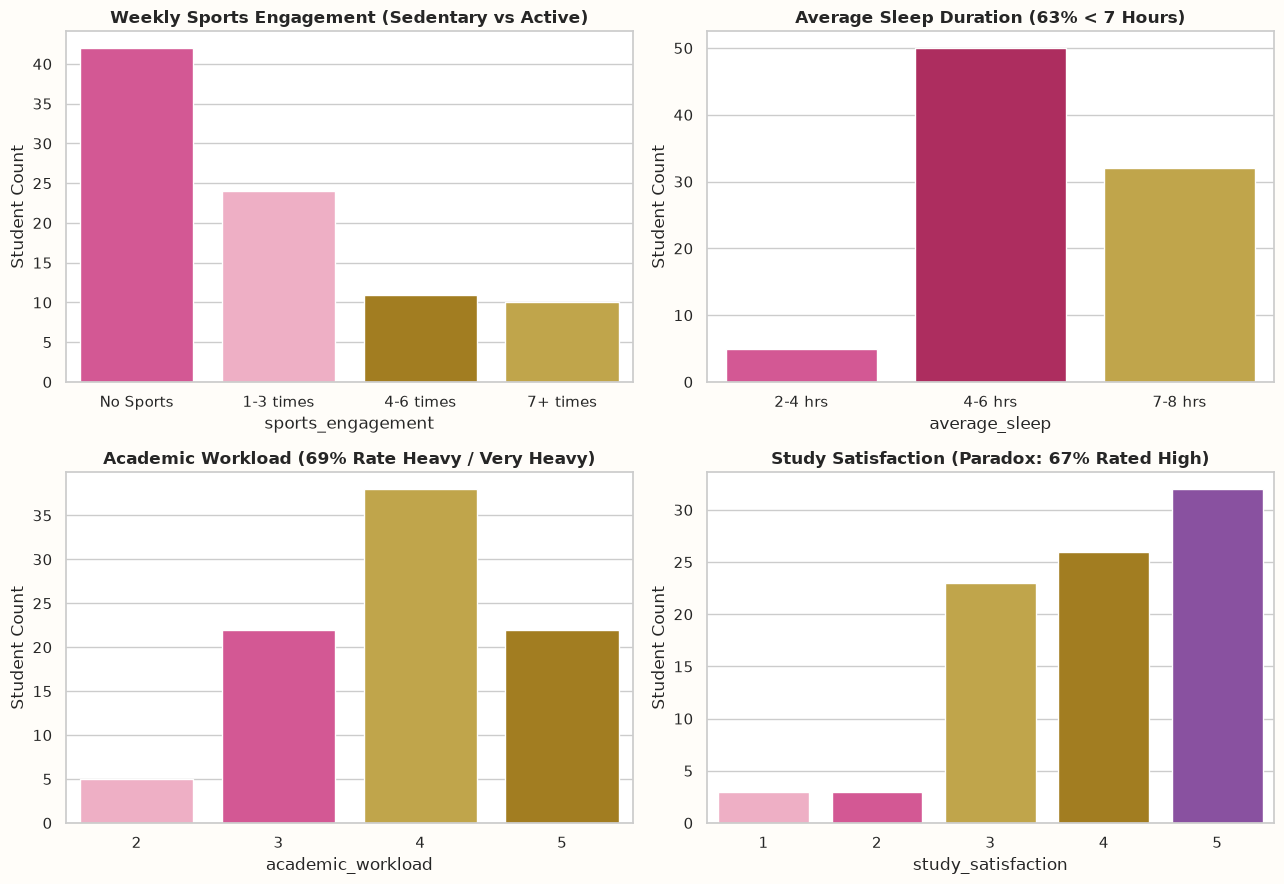

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.patch.set_facecolor(LIGHT_CREAM)

# Sports Engagement
sns.countplot(ax=axes[0, 0], data=df, x='sports_engagement', 
              order=['No Sports', '1-3 times', '4-6 times', '7+ times'], 
              palette=[ROSE_PINK, SOFT_PINK, GOLD, DARK_GOLD], hue='sports_engagement', legend=False)
axes[0, 0].set_title('Weekly Sports Engagement (Sedentary vs Active)', weight='bold')
axes[0, 0].set_ylabel('Student Count')

# Average Sleep
sns.countplot(ax=axes[0, 1], data=df, x='average_sleep', 
              order=['2-4 hrs', '4-6 hrs', '7-8 hrs'], 
              palette=[DEEP_ROSE, ROSE_PINK, GOLD], hue='average_sleep', legend=False)
axes[0, 1].set_title('Average Sleep Duration (63% < 7 Hours)', weight='bold')
axes[0, 1].set_ylabel('Student Count')

# Academic Workload
sns.countplot(ax=axes[1, 0], data=df, x='academic_workload', 
              palette=[SOFT_PINK, ROSE_PINK, GOLD, DARK_GOLD], hue='academic_workload', legend=False)
axes[1, 0].set_title('Academic Workload (69% Rate Heavy / Very Heavy)', weight='bold')
axes[1, 0].set_ylabel('Student Count')

# Study Satisfaction
sns.countplot(ax=axes[1, 1], data=df, x='study_satisfaction', 
              palette=[SOFT_PINK, ROSE_PINK, GOLD, DARK_GOLD, '#8E44AD'], hue='study_satisfaction', legend=False)
axes[1, 1].set_title('Study Satisfaction (Paradox: 67% Rated High)', weight='bold')
axes[1, 1].set_ylabel('Student Count')

plt.tight_layout()
plt.show()


## 4. Correlation Analysis: Clinical Triad & Social Buffers

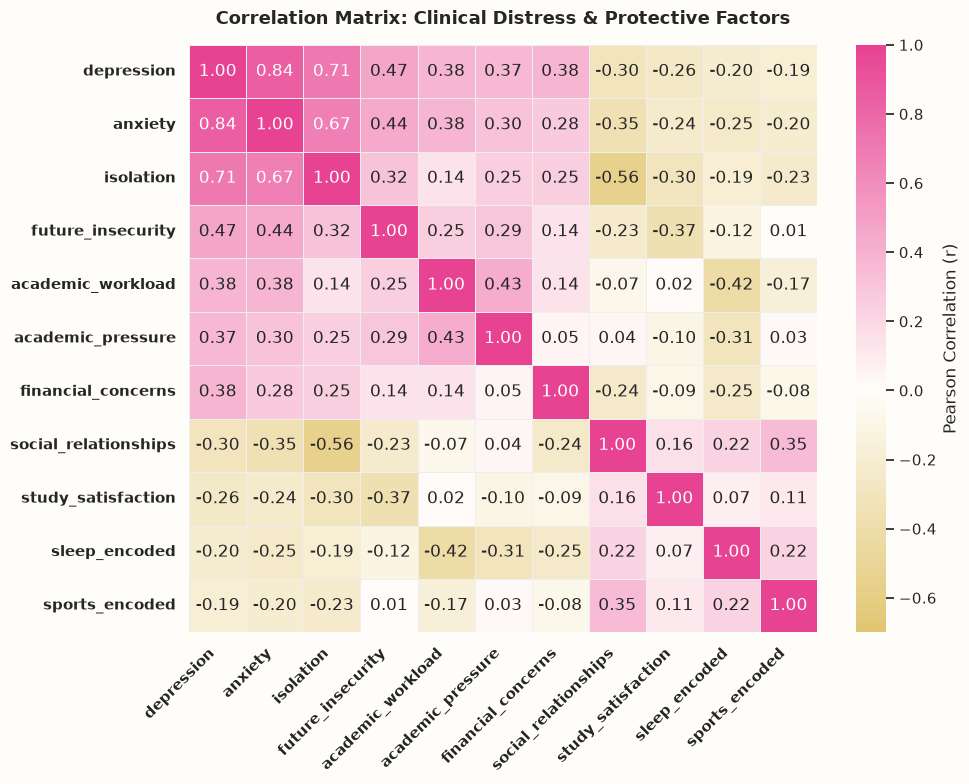

In [6]:
cmap_gold_pink = LinearSegmentedColormap.from_list('gold_pink', [GOLD, '#FFFDF9', ROSE_PINK])

core_vars = ['depression', 'anxiety', 'isolation', 'future_insecurity', 
             'academic_workload', 'academic_pressure', 'financial_concerns', 
             'social_relationships', 'study_satisfaction', 'sleep_encoded', 'sports_encoded']
corr_core = df[core_vars].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_core, annot=True, fmt='.2f', cmap=cmap_gold_pink, center=0, vmin=-0.7, vmax=1.0, 
            cbar_kws={'label': 'Pearson Correlation (r)'}, linewidths=0.5, linecolor='#EEEEEE')
plt.title('Correlation Matrix: Clinical Distress & Protective Factors', fontsize=13, weight='bold', pad=15)
plt.xticks(rotation=45, ha='right', weight='bold')
plt.yticks(weight='bold')
plt.tight_layout()
plt.show()


## 5. Unsupervised Model Selection & Clustering Benchmarking

Comparing K-Means, Agglomerative Hierarchical Clustering, and Gaussian Mixture Models (GMM) across $k \in [2, 5]$ using Silhouette Scores.


In [7]:
cluster_cols = ['depression', 'anxiety', 'isolation', 'future_insecurity', 
                'academic_pressure', 'academic_workload', 'study_satisfaction',
                'sleep_encoded', 'sports_encoded', 'social_relationships']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cluster_cols])

benchmark_results = []
for k in range(2, 6):
    # K-Means
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km_labels = km.fit_predict(X_scaled)
    sil_km = silhouette_score(X_scaled, km_labels)
    
    # Agglomerative
    agg = AgglomerativeClustering(n_clusters=k)
    agg_labels = agg.fit_predict(X_scaled)
    sil_agg = silhouette_score(X_scaled, agg_labels)
    
    # GMM
    gmm = GaussianMixture(n_components=k, random_state=42)
    gmm_labels = gmm.fit_predict(X_scaled)
    sil_gmm = silhouette_score(X_scaled, gmm_labels)
    
    benchmark_results.append({
        'Clusters (k)': k, 
        'K-Means': round(sil_km, 3), 
        'Agglomerative': round(sil_agg, 3), 
        'GMM': round(sil_gmm, 3)
    })

bench_df = pd.DataFrame(benchmark_results)
print('=== Clustering Benchmark Table ===')
print(bench_df.to_string(index=False))


=== Clustering Benchmark Table ===
 Clusters (k)  K-Means  Agglomerative   GMM
            2    0.213          0.214 0.199
            3    0.166          0.134 0.091
            4    0.147          0.130 0.096
            5    0.155          0.141 0.111


## 6. Profile Characterization & 2D PCA Visualization

=== Mean Feature Values by Stress Profile ===
                                         depression  anxiety  isolation  future_insecurity  academic_pressure  academic_workload  study_satisfaction  sleep_encoded  sports_encoded  social_relationships
stress_profile                                                                                                                                                                                           
Profile 1: Resilient / Low Stress (25%)        1.86     2.05       2.27               2.09               2.73               3.09                4.09           1.73            0.91                  2.82
Profile 2: Socially Buffered (26%)             2.61     2.52       2.22               2.57               4.17               4.22                4.35           1.17            1.39                  3.91
Profile 3: Severe Distress (48%)               4.26     4.21       4.31               3.74               4.12               4.12                3.

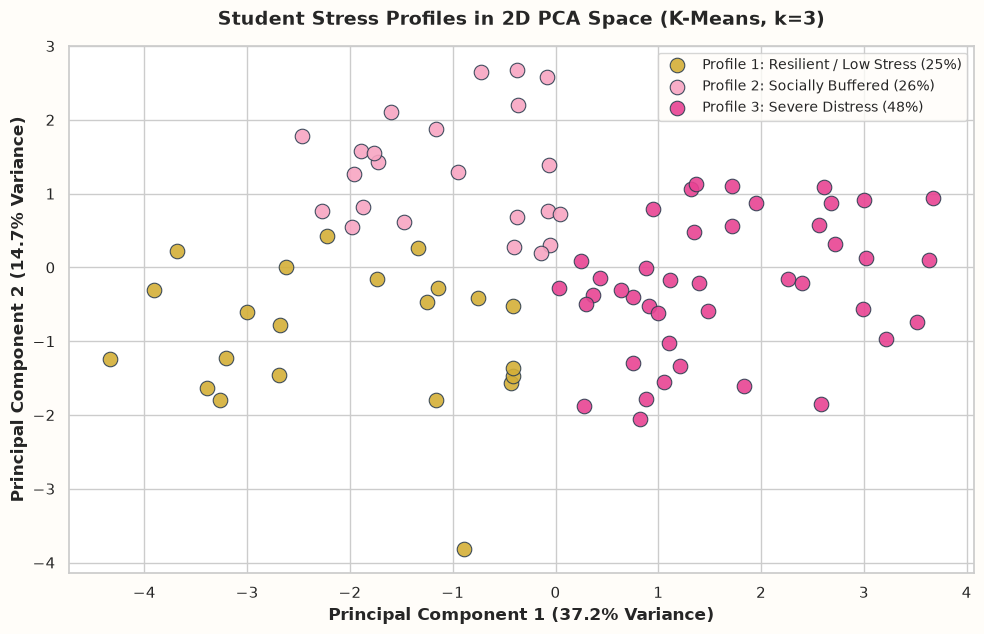

In [8]:
# Train selected optimal model: K-Means (k=3)
optimal_kmeans = KMeans(n_clusters=3, random_state=42, n_init=25)
df['cluster'] = optimal_kmeans.fit_predict(X_scaled)

# Assign clinical profile labels by depression severity
dep_means = df.groupby('cluster')['depression'].mean().to_dict()
sorted_c = sorted(dep_means.keys(), key=lambda x: dep_means[x])

profile_names = {
    sorted_c[0]: 'Profile 1: Resilient / Low Stress (25%)',
    sorted_c[1]: 'Profile 2: Socially Buffered (26%)',
    sorted_c[2]: 'Profile 3: Severe Distress (48%)'
}
df['stress_profile'] = df['cluster'].map(profile_names)

# Profile Statistics
profile_summary = df.groupby('stress_profile')[cluster_cols].mean()
print('=== Mean Feature Values by Stress Profile ===')
print(profile_summary.round(2).to_string())

# PCA Projection
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
df['pca1'] = coords[:, 0]
df['pca2'] = coords[:, 1]

plt.figure(figsize=(10, 6.5))
cluster_colors = {
    'Profile 1: Resilient / Low Stress (25%)': GOLD,
    'Profile 2: Socially Buffered (26%)': SOFT_PINK,
    'Profile 3: Severe Distress (48%)': ROSE_PINK
}

for name, color in cluster_colors.items():
    sub = df[df['stress_profile'] == name]
    plt.scatter(sub['pca1'], sub['pca2'], label=name, color=color, s=110, edgecolors='#2C3E50', linewidth=0.8, alpha=0.9)

plt.title('Student Stress Profiles in 2D PCA Space (K-Means, k=3)', fontsize=14, weight='bold', pad=15)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)', weight='bold')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)', weight='bold')
plt.legend(frameon=True, facecolor=LIGHT_CREAM, fontsize=10)
plt.tight_layout()
plt.show()


## 7. Gender Disparity Analysis

Examining how student stress profiles differ between male and female cohorts to address the final component of the research question.


=== Percentage Breakdown within Gender Cohorts (%) ===
gender                                   Female  Male
stress_profile                                       
Profile 1: Resilient / Low Stress (25%)    25.0  25.4
Profile 2: Socially Buffered (26%)         12.5  31.7
Profile 3: Severe Distress (48%)           62.5  42.9


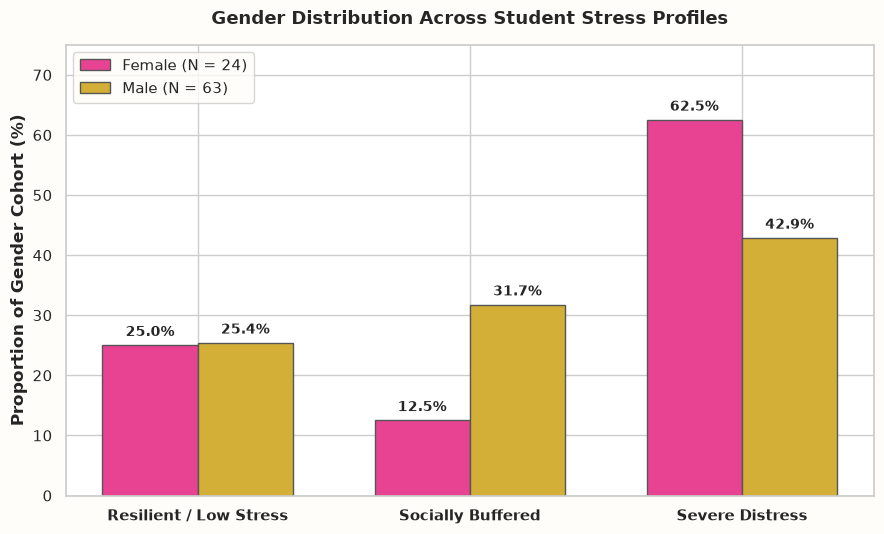

In [9]:
gender_ct = pd.crosstab(df['stress_profile'], df['gender'], normalize='columns') * 100
print('=== Percentage Breakdown within Gender Cohorts (%) ===')
print(gender_ct.round(1))

# Visualization
plt.figure(figsize=(9, 5.5))
x = np.arange(len(gender_ct.index))
width = 0.35

rects1 = plt.bar(x - width/2, gender_ct['Female'], width, label='Female (N = 24)', color=ROSE_PINK, edgecolor='#555555')
rects2 = plt.bar(x + width/2, gender_ct['Male'], width, label='Male (N = 63)', color=GOLD, edgecolor='#555555')

plt.title('Gender Distribution Across Student Stress Profiles', fontsize=13, weight='bold', pad=15)
plt.ylabel('Proportion of Gender Cohort (%)', weight='bold')
plt.xticks(x, [i.split(':')[1].split('(')[0].strip() for i in gender_ct.index], weight='bold')
plt.legend(frameon=True, facecolor=LIGHT_CREAM)

for rect in rects1:
    h = rect.get_height()
    plt.text(rect.get_x() + rect.get_width()/2, h + 1, f'{h:.1f}%', ha='center', va='bottom', weight='bold', fontsize=10)
for rect in rects2:
    h = rect.get_height()
    plt.text(rect.get_x() + rect.get_width()/2, h + 1, f'{h:.1f}%', ha='center', va='bottom', weight='bold', fontsize=10)

plt.ylim(0, 75)
plt.tight_layout()
plt.show()


## 8. Summary of Findings & Research Conclusions

1. **Unsupervised Identification**:
   - Students naturally cluster into three distinct behavioral/clinical archetypes: **Resilient (25%)**, **Socially Buffered (26%)**, and **Severe Distress (48%)**.
2. **Key Predictive Variables**:
   - **Quality of Social Relationships ($r = -0.56$ with isolation)** is the primary protective buffer differentiating Profile 2 (carrying heavy workloads without depression) from Profile 3 (carrying heavy workloads with clinical depression).
   - **Future Insecurity** and **Average Sleep (< 6 hours)** are the primary catalysts pushing students into severe distress.
3. **Gender Disparities**:
   - Females are disproportionately represented in the Severe Distress profile (**62.5%** of females vs. **42.9%** of males).
   - Females experience distress primarily as performance anxiety under heavy workloads, while males experience distress primarily as depressive symptoms tied to career and future uncertainty.


## 9. Acknowledgments & AI Pair-Programming Disclosure

This project was executed independently by **Zuhair Syd** with AI pair-programming support from **Google Gemini**. 
* **Scope of AI Assistance:** Assistance with exploratory Python script generation, visualization colorway design (Gold & Rose-Pink palette), LaTeX markdown drafting, and baseline code optimization.
* **Student Ownership & Rigor:** All methodological decisions, feature pruning (e.g. dropping degree_level, isolating demographic confounders via Cramér's V), model selection rationale (=3$ vs =2$), and clinical profiling interpretations were directed, audited, and verified by Zuhair Syd.
